# 03 · 时间序列基础：平稳性、自相关与单位根

**为什么这一章必须在回归之前？** 时间序列回归的标准推断（t 检验、R²）依赖于变量是 **平稳的 (stationary)**。
如果把两个互不相关的随机游走 (random walk) 做回归，你会以很高的概率得到 "显著" 的系数 ——
这就是 **伪回归 (spurious regression)**（Granger & Newbold 1974）。CPI 指数和油价水平都很像随机游走。

**学习目标**

1. 弱平稳的定义；AR(1) 的均值、方差、自相关函数的推导。
2. 用 Monte Carlo 亲眼看到伪回归。
3. 推导 Dickey-Fuller 检验，理解为什么它的临界值不是 t 分布的临界值。
4. 从零实现 ADF 检验并与 `statsmodels.adfuller` 对照；配合 KPSS 判断真实序列的积分阶数。

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.tsa.stattools import acf as sm_acf
from statsmodels.tools.sm_exceptions import InterpolationWarning
from statsmodels.tsa.stattools import adfuller, kpss

from economic_lab.data import transforms as tf
from economic_lab.data.build import load_dataset
from economic_lab.econometrics.timeseries import acf, adf_test, ljung_box, simulate_ar1
from economic_lab.visualization import SERIES, use_lab_style

use_lab_style()
rng = np.random.default_rng(2026)
q = load_dataset("quarterly")
DATA_KIND = q.attrs["data_kind"]
print("DATA KIND:", DATA_KIND.upper())

DATA KIND: REAL


## Part 1 · 经济直觉

* **平稳**：序列围绕一个固定均值波动，冲击的影响会逐渐消失。季度通胀率、油价的季度变化率大致如此。
* **单位根 / 随机游走**：冲击的影响 **永久存在**，序列没有可回归的均值。价格 *水平*（CPI 指数、油价）大致如此。
* 经济含义：如果油价是随机游走，今天 10% 的油价上涨在预期上是永久性的 —— 这会影响企业是否调价。

## Part 2 · 数学表述

**弱平稳 (weak/covariance stationarity)**：对所有 $t$ 和 $k$，
$E[y_t]=\mu$，$\operatorname{Var}(y_t)=\gamma_0<\infty$，$\operatorname{Cov}(y_t,y_{t-k})=\gamma_k$ 只依赖于 $k$。

**AR(1)**：$y_t = c + \phi y_{t-1} + \varepsilon_t$，$\varepsilon_t \sim \text{iid}(0,\sigma^2)$。

## Part 3 · 推导

若 $|\phi|<1$ 且过程平稳，对两边取期望：$\mu = c + \phi\mu \Rightarrow \mu = c/(1-\phi)$。

令 $\tilde y_t = y_t-\mu$，则 $\tilde y_t = \phi\tilde y_{t-1}+\varepsilon_t$。两边取方差，且 $\tilde y_{t-1}$ 与 $\varepsilon_t$ 不相关：
$$\gamma_0 = \phi^2\gamma_0 + \sigma^2 \;\Rightarrow\; \gamma_0 = \frac{\sigma^2}{1-\phi^2}.$$
两边乘以 $\tilde y_{t-k}$ 再取期望：$\gamma_k = \phi\gamma_{k-1} \Rightarrow \rho_k = \gamma_k/\gamma_0 = \phi^k$。

**随机游走** ($\phi=1, c=0$)：反复代入得 $y_t = y_0 + \sum_{s=1}^{t}\varepsilon_s$，所以 $\operatorname{Var}(y_t)=t\sigma^2$ ——
方差随时间增长，不满足平稳性。冲击 $\varepsilon_s$ 对之后所有 $y_t$ 的影响都是 1（永久）。

半衰期 (half-life)：冲击衰减一半所需期数 $h$ 满足 $\phi^h = 0.5$，即 $h=\ln 0.5/\ln\phi$。$\phi=0.5$ 时 1 期；$\phi=0.95$ 时约 13.5 期。

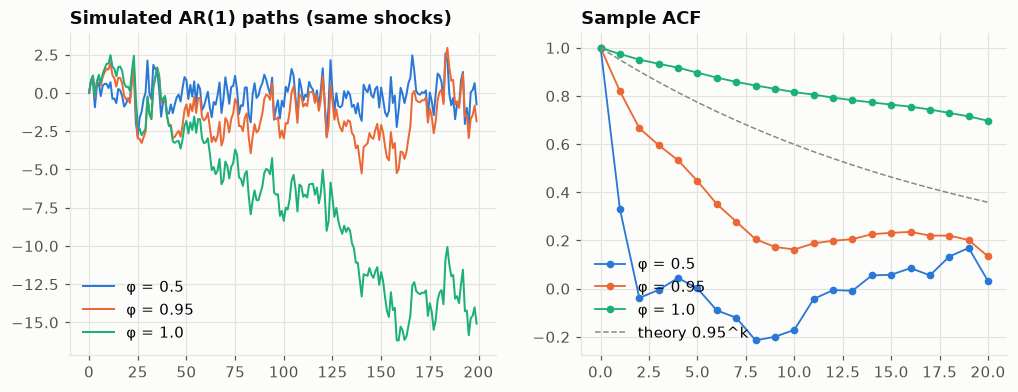

half-life for phi=0.95: 13.5 periods


In [2]:
n = 200
paths = {phi: simulate_ar1(n, phi, seed=1) for phi in (0.5, 0.95, 1.0)}
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for (phi, y), color in zip(paths.items(), SERIES):
    axes[0].plot(y, color=color, linewidth=1.3, label=f"φ = {phi}")
    axes[1].plot(acf(y, 20), "o-", color=color, markersize=4, linewidth=1.2, label=f"φ = {phi}")
axes[1].plot(0.95 ** np.arange(21), color="#8a8984", linestyle="--", linewidth=1, label="theory 0.95^k")
axes[0].set_title("Simulated AR(1) paths (same shocks)")
axes[1].set_title("Sample ACF")
axes[0].legend(); axes[1].legend()
plt.show()

print("half-life for phi=0.95:", round(np.log(0.5) / np.log(0.95), 1), "periods")

### 交互：改变 $\phi$ 和样本长度

需要 `uv sync --extra interactive`（安装 `ipywidgets`）。未安装时会显示静态图。

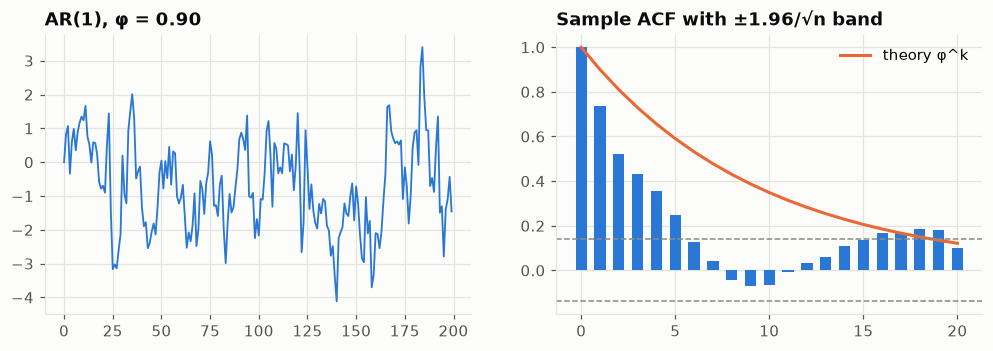

In [3]:
def plot_ar1(phi=0.9, n=200, seed=1):
    y = simulate_ar1(n, phi, seed=seed)
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.3))
    axes[0].plot(y, color=SERIES[0], linewidth=1.2)
    axes[0].set_title(f"AR(1), φ = {phi:.2f}")
    r = acf(y, 20)
    axes[1].bar(range(21), r, color=SERIES[0], width=0.6)
    if abs(phi) < 1:
        axes[1].plot(phi ** np.arange(21), color=SERIES[1], label="theory φ^k")
        axes[1].legend()
    axes[1].axhline(1.96 / np.sqrt(n), color="#8a8984", linestyle="--", linewidth=1)
    axes[1].axhline(-1.96 / np.sqrt(n), color="#8a8984", linestyle="--", linewidth=1)
    axes[1].set_title("Sample ACF with ±1.96/√n band")
    plt.show()

try:
    from ipywidgets import FloatSlider, IntSlider, interact
    interact(plot_ar1, phi=FloatSlider(value=0.9, min=-0.95, max=1.0, step=0.05),
             n=IntSlider(value=200, min=30, max=1000, step=10), seed=IntSlider(value=1, min=0, max=50))
except ImportError:
    plot_ar1()

## Part 4 · 伪回归：一个 Monte Carlo 实验

生成两个 **独立** 的序列 $x_t, y_t$，回归 $y_t=\alpha+\beta x_t+u_t$，用常规 t 检验检验 $H_0:\beta=0$（真值确实为 0）。
在 5% 显著性水平下，正确的检验应该只有约 5% 的拒绝率。

我们用最简单的 NumPy 最小二乘来写这个循环（它就是 notebook 04 中 OLS 的核心）：
$\hat\beta = (X'X)^{-1}X'y$，$\widehat{\operatorname{Var}}(\hat\beta)=s^2(X'X)^{-1}$。

In [4]:
def t_stat_slope(y, x):
    X = np.column_stack([np.ones_like(x), x])
    beta, *_ = np.linalg.lstsq(X, y, rcond=None)
    u = y - X @ beta
    s2 = u @ u / (len(y) - 2)
    cov = s2 * np.linalg.inv(X.T @ X)
    return beta[1] / np.sqrt(cov[1, 1])

def rejection_rate(phi, n=100, reps=2000, seed=0):
    r = np.random.default_rng(seed)
    t = np.empty(reps)
    for i in range(reps):
        e = r.standard_normal((n, 2))
        x, y = np.zeros(n), np.zeros(n)
        for s in range(1, n):
            x[s] = phi * x[s - 1] + e[s, 0]
            y[s] = phi * y[s - 1] + e[s, 1]
        t[i] = t_stat_slope(y, x)
    return np.mean(np.abs(t) > 1.96), t

results = {phi: rejection_rate(phi) for phi in (0.0, 0.5, 0.9, 1.0)}
pd.Series({phi: r[0] for phi, r in results.items()}, name="share of |t| > 1.96 (true beta = 0)")

0.0    0.0500
0.5    0.1250
0.9    0.5160
1.0    0.7715
Name: share of |t| > 1.96 (true beta = 0), dtype: float64

当 $\phi=1$（两个独立随机游走）时，大约四分之三的回归 "发现" 了显著关系！原因：
在 $H_0$ 下残差 $u_t = y_t-\alpha$ 本身就是随机游走，严重违反 OLS 推断所需的 "误差无序列相关且方差有限" 的假设，
$s^2(X'X)^{-1}$ 严重低估了 $\hat\beta$ 的真实抽样方差。即使 $\phi=0.9$ 拒绝率也明显超过 5% —— 高度持续的序列同样危险。

**结论**：不要直接用 CPI *水平* 对油价 *水平* 回归。要么使用平稳变换（通胀率、油价变化率），要么证明两者 **协整**（notebook 05）。

## Part 5 · Dickey-Fuller 检验

### 推导

从 $y_t = \rho y_{t-1} + \varepsilon_t$ 两边减去 $y_{t-1}$：
$$\Delta y_t = \gamma y_{t-1} + \varepsilon_t,\qquad \gamma=\rho-1.$$
$H_0:\gamma=0$（单位根）vs $H_1:\gamma<0$（平稳）。检验统计量就是 OLS 的 t 比值 $\hat\gamma/\operatorname{se}(\hat\gamma)$。

**为什么不能用 t 分布？** 在 $H_0$ 下 $y_{t-1}$ 是随机游走，$\frac{1}{T^2}\sum y_{t-1}^2$ 不收敛到常数，
而是收敛到布朗运动的泛函 $\sigma^2\int_0^1 W(r)^2dr$。因此 t 比值的极限分布是
$$\frac{\tfrac12\left(W(1)^2-1\right)}{\left(\int_0^1 W(r)^2dr\right)^{1/2}},$$
它向左偏移，5% 临界值约为 −1.95（无常数项）、−2.86（有常数项）、−3.41（有趋势项），而不是 −1.645。
下面用模拟来 "看到" 这个分布。

**ADF 中的 "Augmented"**：若 $\Delta y_t$ 本身序列相关，在回归中加入 $\Delta y_{t-1},\dots,\Delta y_{t-p}$ 吸收自相关，
使误差近似白噪声：
$$\Delta y_t = a + \delta t + \gamma y_{t-1} + \sum_{i=1}^{p}\phi_i\Delta y_{t-i} + e_t.$$
确定性项的选择：数据有明显趋势（价格水平）用常数 + 趋势 (`ct`)；围绕非零均值波动（通胀率）用常数 (`c`)。

simulated 5% critical value (constant): -2.85
normal 5% one-sided critical value     : -1.645


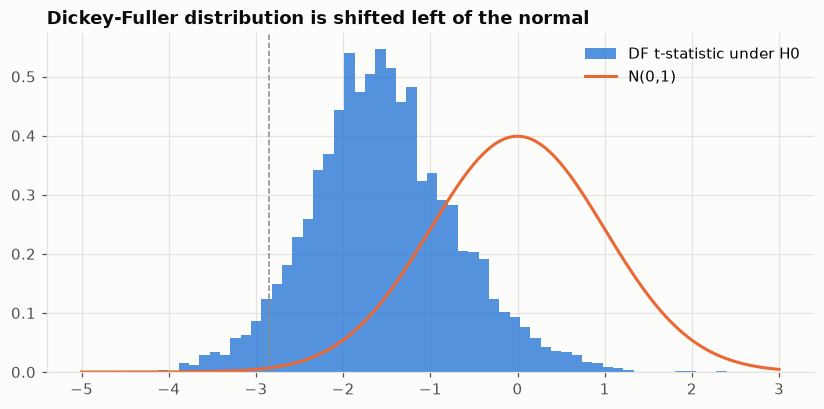

In [5]:
def df_tstat(y, const=True):
    dy, ylag = np.diff(y), y[:-1]
    X = np.column_stack([ylag, np.ones_like(ylag)]) if const else ylag[:, None]
    beta, *_ = np.linalg.lstsq(X, dy, rcond=None)
    u = dy - X @ beta
    s2 = u @ u / (len(dy) - X.shape[1])
    return beta[0] / np.sqrt(s2 * np.linalg.inv(X.T @ X)[0, 0])

T, reps = 200, 4000
df_stats = np.array([df_tstat(np.cumsum(rng.standard_normal(T))) for _ in range(reps)])
print("simulated 5% critical value (constant):", np.quantile(df_stats, 0.05).round(2))
print("normal 5% one-sided critical value     :", -1.645)

fig, ax = plt.subplots()
ax.hist(df_stats, bins=60, density=True, color=SERIES[0], alpha=0.8, label="DF t-statistic under H0")
grid = np.linspace(-5, 3, 300)
ax.plot(grid, np.exp(-grid**2 / 2) / np.sqrt(2 * np.pi), color=SERIES[1], label="N(0,1)")
ax.axvline(np.quantile(df_stats, 0.05), color="#8a8984", linestyle="--", linewidth=1)
ax.set_title("Dickey-Fuller distribution is shifted left of the normal")
ax.legend()
plt.show()

### Part 5b · 从零实现 vs `statsmodels`

`economic_lab.econometrics.timeseries.adf_test` 自己构建 ADF 回归并用我们的 OLS 估计；
只有非标准分布的 p 值和临界值来自 MacKinnon (1994, 2010) 的响应面（`statsmodels.tsa.adfvalues`）。
滞后阶数用 AIC 选择，且所有候选模型在 **同一样本** 上比较 —— 和 `adfuller` 完全一致：

In [6]:
y = np.cumsum(rng.standard_normal(250))
rows = []
for trend in ["n", "c", "ct"]:
    ours = adf_test(y, trend=trend)
    ref = adfuller(y, regression=trend, autolag="AIC", result_object=False)
    rows.append({"trend": trend, "ours_stat": ours.stat, "statsmodels_stat": ref[0],
                 "ours_lags": ours.lags, "sm_lags": ref[2], "ours_p": ours.p_value, "sm_p": ref[1]})
pd.DataFrame(rows).round(6)

,trend,ours_stat,statsmodels_stat,ours_lags,sm_lags,ours_p,sm_p
0,n,0.970484,0.970484,0,0,0.911806,0.911806
1,c,-0.288075,-0.288075,0,0,0.927176,0.927176
2,ct,-3.326567,-3.326567,1,1,0.062000,0.062000


## Part 6 · 真实数据：积分阶数

我们同时报告 ADF（$H_0$：单位根）和 KPSS（$H_0$：平稳）。两者结论一致时更有把握；
不一致时（常见于小样本、结构突变）要谨慎。样本从 1992Q1 开始：新西兰 1989 年《储备银行法》之后，
通胀目标制在 1990–1991 年完成去通胀，1992 年以后通胀进入较稳定的区间（之前的高通胀时期会使 "平稳" 的通胀率看起来像有趋势）。

In [7]:
s = q.loc["1992":, ["cpi", "oil_nzd"]].dropna()
series = {
    "log CPI (level)": (100 * np.log(s["cpi"]), "ct"),
    "CPI inflation q/q": (tf.pct_change(s["cpi"], 1, freq="Q"), "c"),
    "log oil price NZD (level)": (100 * np.log(s["oil_nzd"]), "ct"),
    "oil price change q/q (log)": (tf.log_diff(s["oil_nzd"], 1, freq="Q"), "c"),
}
rows = []
for name, (x, trend) in series.items():
    x = x.dropna()
    a = adf_test(x.to_numpy(), trend=trend)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", InterpolationWarning)  # p-value outside table range: reported as a bound
        k = kpss(x, regression=trend, nlags="auto", result_object=False)
    rows.append({"series": name, "deterministic": trend, "n": len(x),
                 "ADF stat": a.stat, "ADF p": a.p_value, "ADF lags": a.lags,
                 "KPSS stat": k[0], "KPSS p (bounded)": k[1]})
unit_roots = pd.DataFrame(rows).set_index("series").round(3)
unit_roots

,deterministic,n,ADF stat,ADF p,ADF lags,KPSS stat,KPSS p (bounded)
series,,,,,,,
log CPI (level),ct,138,-1.470,0.839,4,0.127,0.085
CPI inflation q/q,c,137,-5.296,0.000,1,0.319,0.100
log oil price NZD (level),ct,138,-2.729,0.224,1,0.279,0.010
oil price change q/q (log),c,137,-9.991,0.000,0,0.049,0.100


**如何解读**（下面的描述对应真实数据 1992Q1–2026Q2（RBNZ M1 CPI）的输出；合成数据下数字不同）：

* **log 油价**：ADF 不拒绝单位根，KPSS 在 1% 水平拒绝趋势平稳 → 两个检验一致，视为 I(1)。
* **log CPI**：ADF 不拒绝单位根，但 KPSS（含趋势）在 5% 水平 **也不拒绝** 趋势平稳（p ≈ 0.085，只在 10% 水平边际拒绝）
  → 两个检验在常用的 5% 水平上 **矛盾**，结论取决于显著性水平的选择。
  这在 30 多年的季度样本中很常见：通胀目标制下 log CPI 接近 "确定性趋势 + 高度持续的偏离"，
  单位根检验的功效 (power) 很低，区分不了 $\phi=1$ 与 $\phi=0.95$。稳妥的做法是 **不依赖 CPI 水平的平稳性**。
* **通胀率与油价变化率**：ADF 强烈拒绝单位根，KPSS 不拒绝平稳 → I(0)。
* `statsmodels` 的 KPSS p 值只在 [0.01, 0.10] 区间内插值，超出范围时返回边界值，所以列名标注为 "bounded"
  （p = 0.10 表示 "≥ 0.10"）。

因此 notebook 04/05 的基准回归使用 **通胀率对油价变化率**。水平值之间的关系只有在协整时才有意义。

## Part 7 · 诊断：残差是不是白噪声？

Ljung-Box 统计量 $Q = n(n+2)\sum_{k=1}^{h}\hat\rho_k^2/(n-k) \sim \chi^2_{h-m}$，其中 $m$ 是模型中估计的 ARMA 参数个数。
下面检验季度通胀本身是否有自相关（若有，预测模型就应该包含通胀的滞后项）：

In [8]:
pi = tf.pct_change(s["cpi"], 1, freq="Q").dropna()
print("our ACF   :", acf(pi, 4).round(3))
print("statsmodels:", sm_acf(pi, nlags=4).round(3))
print("Ljung-Box (8 lags):", {k: round(v, 4) for k, v in ljung_box(pi, 8).items()})

our ACF   : [1.    0.401 0.282 0.228 0.224]
statsmodels: [1.    0.401 0.282 0.228 0.224]
Ljung-Box (8 lags): {'Q': 55.0764, 'df': 8, 'p_value': 0.0}


## Part 8 · 练习

1. **Easy** — 把伪回归实验中的样本量从 100 改为 400。$\phi=1$ 时拒绝率是变大还是变小？为什么增加样本量不能解决问题？
2. **Intermediate** — 修改 `df_tstat`，加入线性趋势项，模拟 5% 临界值并与 MacKinnon 的 −3.41（大样本）比较。
3. **Advanced** — 对两个独立随机游走，先差分再回归 $\Delta y_t$ 对 $\Delta x_t$，计算拒绝率。然后讨论：
   如果 $y$ 和 $x$ 实际上是 **协整** 的，只用差分回归会丢失什么信息？

## 参考答案

In [9]:
# Exercise 1: with random walks the rejection rate rises with n; the t-statistic diverges at rate sqrt(n)
for n_ in (100, 400):
    print(n_, rejection_rate(1.0, n=n_, reps=1000, seed=1)[0])

100 0.77


400 0.894


In [10]:
# Exercise 2
def df_tstat_trend(y):
    dy, ylag = np.diff(y), y[:-1]
    X = np.column_stack([ylag, np.ones_like(ylag), np.arange(len(ylag), dtype=float)])
    beta, *_ = np.linalg.lstsq(X, dy, rcond=None)
    u = dy - X @ beta
    return beta[0] / np.sqrt(u @ u / (len(dy) - 3) * np.linalg.inv(X.T @ X)[0, 0])

sims = [df_tstat_trend(np.cumsum(rng.standard_normal(500))) for _ in range(3000)]
print("simulated 5% critical value with trend:", np.quantile(sims, 0.05).round(2))

simulated 5% critical value with trend: -3.42


In [11]:
# Exercise 3
def rejection_rate_diff(n=100, reps=2000, seed=0):
    r = np.random.default_rng(seed)
    hits = 0
    for _ in range(reps):
        e = r.standard_normal((n, 2))
        hits += abs(t_stat_slope(e[1:, 1], e[1:, 0])) > 1.96  # Δy and Δx are just the iid shocks
    return hits / reps

print("rejection rate after differencing:", rejection_rate_diff())

rejection rate after differencing: 0.0495


差分后拒绝率回到约 5%：差分消除了伪回归。但如果 $y$ 与 $x$ 协整（例如 $y_t-\theta x_t$ 平稳），
那么偏离长期均衡 $y_{t-1}-\theta x_{t-1}$ 会预测未来的 $\Delta y_t$；只用差分的模型丢掉了这个 **误差修正项**，
既损失了长期信息也会使模型设定错误。这正是 notebook 05 中 ECM 要解决的问题。